In [1]:
import numpy as np
import pandas as pd

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data -O data-week-4-homework.csv

--2026-10-19 19:04:33--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘data-week-4-homework.csv’

data-week-4-homewor 100%[===================>] 272.21K  --.-KB/s    in 0.003s  

2026-10-19 19:04:33 (93.0 MB/s) - ‘data-week-4-homework.csv’ saved [278746/278746]



In [4]:
df = pd.read_csv('data-week-4-homework.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
categorical_columns

['lead_source', 'industry', 'employment_status', 'location']

In [8]:
numerical_columns = list(df.dtypes[(df.dtypes == 'float64') | (df.dtypes == 'int64')].index)
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [9]:
df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0.0)

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# Q1 - ROC AUC feature importance

In [12]:
y_train = df_train.converted.values
y_train

array([1, 0, 0, ..., 0, 1, 1], shape=(3000,))

In [13]:
from sklearn.metrics import roc_auc_score

In [14]:
for col in numerical_columns:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(col, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788
converted 1.0


# Q2 - Training the model

In [15]:
from sklearn.feature_extraction import DictVectorizer

In [41]:
numerical_columns.remove('converted')

In [42]:
train_dicts = df_train[categorical_columns + numerical_columns].to_dict(orient='records')

In [43]:
train_dicts[0]

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

In [44]:
dv = DictVectorizer(sparse=False)

In [45]:
X_train = dv.fit_transform(train_dicts)

In [46]:
y_train = df_train.converted.values
y_val = df_val.converted.values

In [47]:
from sklearn.linear_model import LogisticRegression

In [48]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)


In [49]:
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [50]:
val_dicts = df_val[categorical_columns + numerical_columns].to_dict(orient='records')

In [51]:
X_val = dv.transform(val_dicts)

In [52]:
y_pred = model.predict_proba(X_val)[:, 1]

In [53]:
round(roc_auc_score(y_val, y_pred),3)

0.732

# Q3 - Precision and Recall

In [54]:
scores = []
thresholds = np.linspace(0, 1, 101)

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, p, r))

In [55]:
df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

In [56]:
import matplotlib.pyplot as plt

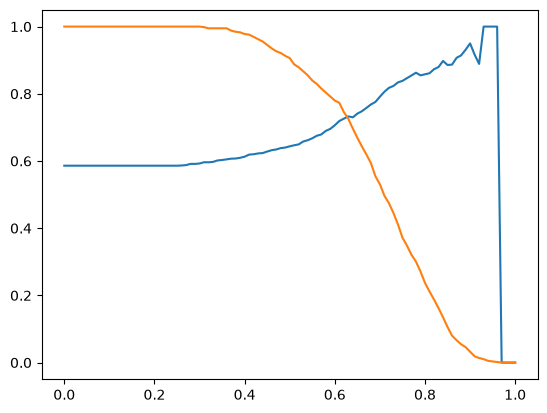

In [57]:
plt.plot(df_scores.threshold, df_scores.precision)
plt.plot(df_scores.threshold, df_scores.recall)

In [58]:
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)]
diff = (valid.precision - valid.recall).abs()
valid.loc[diff.idxmin(), 'threshold']

np.float64(0.63)

# Q4 - F1 score

In [59]:
scores_f1 = []
thresholds = np.linspace(0, 1, 101)

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0

    scores_f1.append((t, f1))

In [60]:
df_f1 = pd.DataFrame(scores_f1, columns=['threshold', 'f1'])

In [61]:
df_f1.loc[df_f1.f1.idxmax()]

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64

# Q5 - 5-Fold CV standard deviation

In [66]:
from sklearn.model_selection import KFold

In [67]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [72]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold.converted.values
    y_val_fold = df_val_fold.converted.values

    train_dicts = df_train_fold[categorical_columns + numerical_columns].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train_fold)

    val_dicts = df_val_fold[categorical_columns + numerical_columns].to_dict(orient='records')
    X_val = dv.transform(val_dicts)
    y_pred = model.predict_proba(X_val)[:, 1]

    scores.append(roc_auc_score(y_val_fold, y_pred))

In [74]:
np.std(scores)

np.float64(0.006853233151022138)

# Q6 - Hyperparameter Tuning

In [76]:
for C in [0.000001, 0.001, 1]:
    scores_c = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
    
        y_train_fold = df_train_fold.converted.values
        y_val_fold = df_val_fold.converted.values
    
        train_dicts = df_train_fold[categorical_columns + numerical_columns].to_dict(orient='records')
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
    
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train_fold)
    
        val_dicts = df_val_fold[categorical_columns + numerical_columns].to_dict(orient='records')
        X_val = dv.transform(val_dicts)
        y_pred = model.predict_proba(X_val)[:, 1]
    
        scores_c.append(roc_auc_score(y_val_fold, y_pred))
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores_c), np.std(scores_c)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
